# Practical 4: Preprocessing, Data Normalization, Noise Elimination, Feature Selection & EDA

**Name:** Vedant Vinod Rakshe

**Aim:** To write Python programs using Pandas, NumPy, Matplotlib and Scikit-learn to handle missing values and duplicate records, normalise data, eliminate noise (outliers), select useful features and perform Exploratory Data Analysis (EDA).

## Part A: Missing Values, Duplicates & Normalization

In [1]:
# Name: Vedant Vinod Rakshe
print("Name: Vedant Vinod Rakshe")
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# Raw data with missing values and duplicate records
raw = {
    "Name":       ["Amit", "Riya", "Amit", "Neha", None, "Riya", "Karan"],
    "Age":        [22, 24, 22, None, 26, 24, 23],
    "Marks":      [85, 90, 85, 78, None, 90, 66],
    "Attendance": [88, 92, 88, None, 75, 92, 80],
}
df_a = pd.DataFrame(raw)
print("Original data:\n", df_a)
print("\nMissing values:\n", df_a.isnull().sum())
print("Duplicate rows:", df_a.duplicated().sum())

# 1. Handle missing values: numeric -> mean, text -> 'Unknown'
for col in ["Age", "Marks", "Attendance"]:
    df_a[col] = df_a[col].fillna(df_a[col].mean())
df_a["Name"] = df_a["Name"].fillna("Unknown")

# 2. Remove duplicate records
df_a = df_a.drop_duplicates().reset_index(drop=True)
print("\nAfter cleaning:\n", df_a.round(2))

# 3. Min-Max normalisation  (x - min) / (max - min)  -> range 0 to 1
num_cols = ["Age", "Marks", "Attendance"]
minmax = (df_a[num_cols] - df_a[num_cols].min()) / (df_a[num_cols].max() - df_a[num_cols].min())
print("\nMin-Max normalised data:\n", minmax.round(3).add_suffix("_MinMax"))

# 4. Z-score standardisation using scikit-learn  (mean 0, std 1)
z = pd.DataFrame(StandardScaler().fit_transform(df_a[num_cols]), columns=num_cols)
print("\nZ-score standardised data:\n", z.round(3).add_suffix("_Z"))

Name: Vedant Vinod Rakshe
Original data:
     Name   Age  Marks  Attendance
0   Amit  22.0   85.0        88.0
1   Riya  24.0   90.0        92.0
2   Amit  22.0   85.0        88.0
3   Neha   NaN   78.0         NaN
4    NaN  26.0    NaN        75.0
5   Riya  24.0   90.0        92.0
6  Karan  23.0   66.0        80.0

Missing values:
 Name          1
Age           1
Marks         1
Attendance    1
dtype: int64
Duplicate rows: 2

After cleaning:
       Name   Age  Marks  Attendance
0     Amit  22.0  85.00       88.00
1     Riya  24.0  90.00       92.00
2     Neha  23.5  78.00       85.83
3  Unknown  26.0  82.33       75.00
4    Karan  23.0  66.00       80.00

Min-Max normalised data:
    Age_MinMax  Marks_MinMax  Attendance_MinMax
0       0.000         0.792              0.765
1       0.500         1.000              1.000
2       0.375         0.500              0.637
3       1.000         0.681              0.000
4       0.250         0.000              0.294

Z-score standardised data:
  

## Part B: Noise Elimination (IQR) & Feature Selection (Variance Threshold)

The age value 100 is noise (an outlier) and the column 'Constant' carries no information, so the outlier row is removed with the IQR rule and the constant feature is dropped with VarianceThreshold.

In [2]:
print("Name: Vedant Vinod Rakshe")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_selection import VarianceThreshold

# -----------------------------
# Sample Dataset
# -----------------------------
data = {
    'Age': [20, 21, 22, 23, 24, 100],   # 100 is an outlier (noise)
    'Marks': [75, 80, 85, 90, 95, 20],
    'Attendance': [85, 88, 90, 92, 94, 50],
    'Constant': [1, 1, 1, 1, 1, 1]      # Constant feature
}
df = pd.DataFrame(data)
print("Original Dataset:")
print(df)

# =====================================
# 1. Noise Elimination (Outlier Removal using the IQR rule)
# =====================================
Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
print(f"\nQ1={Q1}, Q3={Q3}, IQR={IQR}, valid range=[{lower}, {upper}]")

df_clean = df[(df['Age'] >= lower) & (df['Age'] <= upper)]
print("\nDataset after Noise Elimination:")
print(df_clean)

# =====================================
# 2. Feature Selection
# Remove constant or low-variance features
# =====================================
selector = VarianceThreshold(threshold=0.0)
selected = selector.fit_transform(df_clean)
selected_columns = df_clean.columns[selector.get_support()]
print("\nFeature variances:\n", df_clean.var().to_string())
print("\nSelected Features:")
print(selected_columns)

df_selected = df_clean[selected_columns]   # dataset used for EDA

Name: Vedant Vinod Rakshe
Original Dataset:
   Age  Marks  Attendance  Constant
0   20     75          85         1
1   21     80          88         1
2   22     85          90         1
3   23     90          92         1
4   24     95          94         1
5  100     20          50         1

Q1=21.25, Q3=23.75, IQR=2.5, valid range=[17.5, 27.5]

Dataset after Noise Elimination:
   Age  Marks  Attendance  Constant
0   20     75          85         1
1   21     80          88         1
2   22     85          90         1
3   23     90          92         1
4   24     95          94         1

Feature variances:
 Age            2.5
Marks         62.5
Attendance    12.2
Constant       0.0

Selected Features:
Index(['Age', 'Marks', 'Attendance'], dtype='str')


## Part C: Exploratory Data Analysis (EDA)

Name: Vedant Vinod Rakshe

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Age         5 non-null      int64
 1   Marks       5 non-null      int64
 2   Attendance  5 non-null      int64
dtypes: int64(3)
memory usage: 252.0 bytes

Statistical Summary:
             Age      Marks  Attendance
count   5.000000   5.000000     5.00000
mean   22.000000  85.000000    89.80000
std     1.581139   7.905694     3.49285
min    20.000000  75.000000    85.00000
25%    21.000000  80.000000    88.00000
50%    22.000000  85.000000    90.00000
75%    23.000000  90.000000    92.00000
max    24.000000  95.000000    94.00000

Correlation Matrix:
                 Age     Marks  Attendance
Age         1.000000  1.000000    0.995893
Marks       1.000000  1.000000    0.995893
Attendance  0.995893  0.995893    1.000000


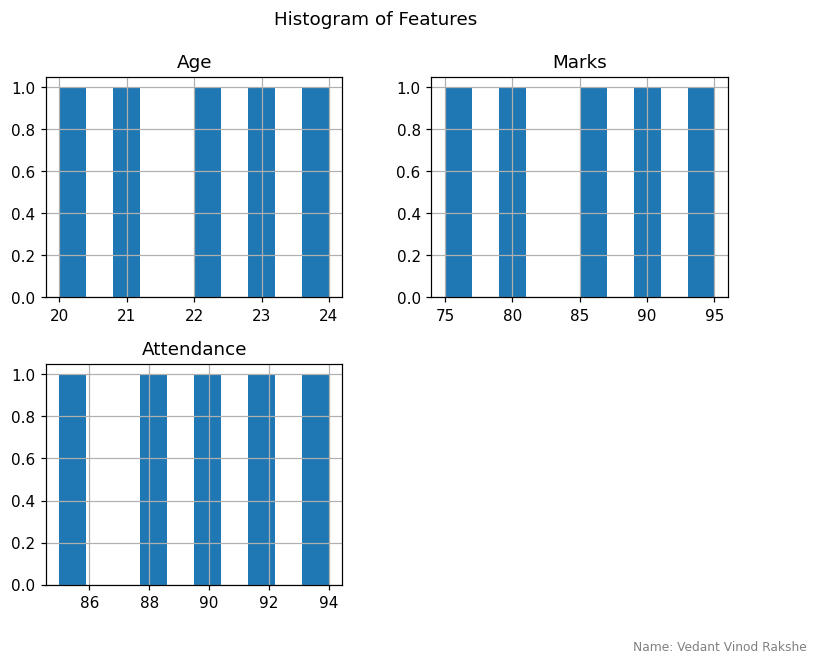

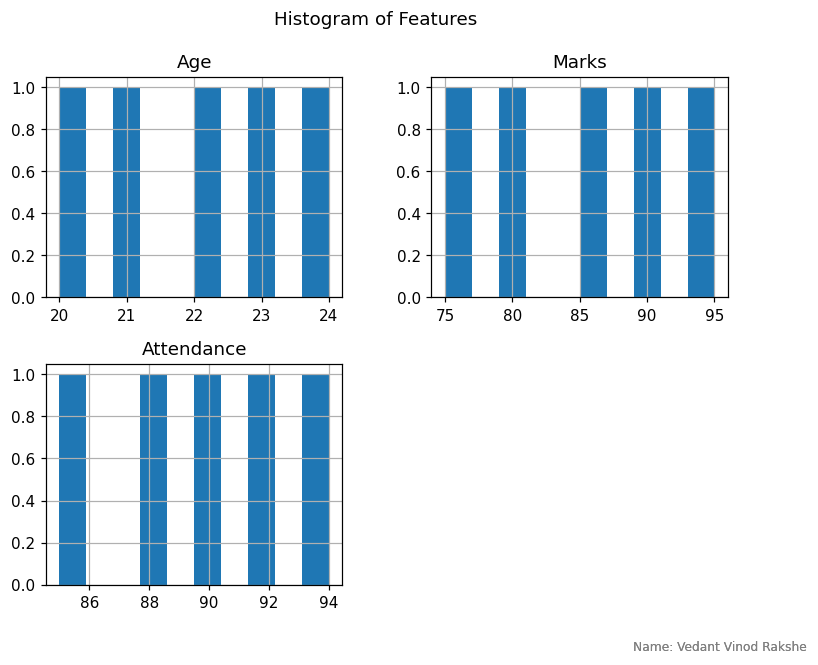

In [3]:
# =====================================
# 3. Exploratory Data Analysis (EDA)
# =====================================
print("Name: Vedant Vinod Rakshe")
print("\nDataset Information:")
df_selected.info()

print("\nStatistical Summary:")
print(df_selected.describe())

print("\nCorrelation Matrix:")
print(df_selected.corr())

# Histogram
df_selected.hist(figsize=(8, 6))
plt.suptitle("Histogram of Features")
plt.gcf().text(0.99, 0.005, "Name: Vedant Vinod Rakshe", ha="right", va="bottom", fontsize=8, color="gray")
plt.savefig("p4_histogram.png", dpi=110, bbox_inches="tight")
plt.show()

# Boxplot
df_selected.boxplot(figsize=(8, 5))
plt.title("Boxplot of Dataset")
plt.gcf().text(0.99, 0.005, "Name: Vedant Vinod Rakshe", ha="right", va="bottom", fontsize=8, color="gray")
plt.savefig("p4_boxplot.png", dpi=110, bbox_inches="tight")
plt.show()

**Conclusion:** Missing values were imputed, duplicates removed and the data was scaled using Min-Max and Z-score normalization. The IQR rule removed the noisy outlier row, VarianceThreshold eliminated the constant feature, and EDA (summary statistics, correlation, histograms and boxplots) was used to understand the cleaned dataset.